# Lecția 2 - Explorarea și preprocesarea datelor

Pasul de preprocesare a datelor este o etapă esențială în dezvoltarea unui model de ML. Datele brute pot conține informații lipsă, valori anormale sau erori. Prin preprocesare, curățăm datele și le transformăm astfel încât să fie utilizabile pentru algoritmii folosiți. În această etapă explorăm și datele pentru a înțelege structura și caracteristicile acestora.

<h2>Setul de date folosit în lecție</h2>

Pentru a putea urmări efectul fiecărei comenzi, lucrăm cu un set mic și fictiv: 12 studenți, pentru care vrem să pregătim datele în vederea unui model care să prezică nota finală.

| Coloană | Ce conține | Tip |
|---|---|---|
| `nume` | numele studentului | text |
| `oras` | orașul | text (categorică) |
| `ore_studiu` | ore de studiu pe săptămână | numerică |
| `puncte_activitate` | puncte de activitate, 0-1000 | numerică |
| `nota` | nota finală | numerică |

Doi termeni pe care îi vom folosi în continuare:

- **variabila țintă** (*target*) este valoarea pe care modelul trebuie să învețe să o prezică; aici, `nota`
- **caracteristicile** (*features*) sunt informațiile din care modelul învață; aici, `ore_studiu`, `puncte_activitate` și, eventual, `oras`

`nume` doar identifică studentul și nu ajută la prezicerea notei, așa că nu ar fi folosit ca intrare pentru model.

<h2>Importarea datelor și manipularea acestora cu pandas</h2>

Cele mai populare biblioteci (oferite sub formă de pachete) din Python pentru a realiza astfel de analize sunt Numpy(https://numpy.org/doc/stable/) și Pandas(https://pandas.pydata.org/docs/reference/index.html). Numpy servește ca model de bază pentru matricele multidimensionale cu care veți lucra, în timp ce Pandas pune la dispoziție o suită întreagă de metode de analiză și vizualizare a datelor. Majoritatea funcțiilor pe care le veți utiliza în acest laborator sunt din biblioteca pandas. Suplimentar, veți folosi și funcții de vizualizare (mai avansate) din biblioteca Matplotlib sau din Seaborn(https://seaborn.pydata.org/tutorial/introduction) (strâns legată de Pandas ).

In [73]:
#Încărcăm pachetele necesare

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Ca lecția să poată fi rulată fără alte fișiere, creăm aici două fișiere CSV, în care am lăsat intenționat câteva câmpuri goale (modulul `os` este folosit doar pentru a crea folderul lor):

In [74]:
os.makedirs("date_lectia2", exist_ok=True)

partea1 = """nume,oras,ore_studiu,puncte_activitate,nota
Ana,Cluj,12,640,8
Mihai,Iași,5,210,5
Elena,Cluj,,720,9
Radu,București,15,810,9
Ioana,Iași,8,390,6
Andrei,,3,150,4
"""

partea2 = """nume,oras,ore_studiu,puncte_activitate,nota
Maria,Cluj,18,930,10
Vlad,București,10,,7
Sofia,Timișoara,7,350,6
Dan,București,14,700,
Irina,Iași,11,560,8
Paul,Cluj,6,300,5
"""

with open("date_lectia2/partea1.csv", "w", encoding="utf-8") as f:
    f.write(partea1)
with open("date_lectia2/partea2.csv", "w", encoding="utf-8") as f:
    f.write(partea2)

`read_csv` citește un fișier CSV și îl transformă într-un **DataFrame**: un tabel cu rânduri și coloane. Câmpurile goale din fișier apar ca `NaN`, adică valoare lipsă.

In [75]:
df1 = pd.read_csv(r"date_lectia2/partea1.csv")
df2 = pd.read_csv(r"date_lectia2/partea2.csv")

print(df1.shape)  # (rânduri, coloane)
df1

(6, 5)


,nume,oras,ore_studiu,puncte_activitate,nota
0,Ana,Cluj,12.0,640,8
1,Mihai,Iași,5.0,210,5
2,Elena,Cluj,NaN,720,9
3,Radu,București,15.0,810,9
4,Ioana,Iași,8.0,390,6
5,Andrei,NaN,3.0,150,4


`to_csv` salvează un DataFrame într-un fișier, iar `mode="a"` adaugă la finalul acestuia. Datele studenților sunt împărțite în două fișiere, așa că le reunim într-unul singur:

In [76]:
df1.to_csv(r"date_lectia2/studenti.csv", index=False)                         # creează fișierul
df2.to_csv(r"date_lectia2/studenti.csv", mode="a", index=False, header=False) # adaugă la final

df = pd.read_csv(r"date_lectia2/studenti.csv")
print(df.shape)

(12, 5)


`index=False` nu scrie indexul în fișier, iar `header=False` nu mai scrie încă o dată numele coloanelor.

**Greșeală frecventă:** dacă omitem acești doi parametri la adăugare, fișierul se strică:

In [77]:
df1.to_csv(r"date_lectia2/gresit.csv", index=False)   # creează fișierul
df2.to_csv(r"date_lectia2/gresit.csv", mode="a")      # adaugă FĂRĂ index=False și header=False

with open(r"date_lectia2/gresit.csv", encoding="utf-8") as f:
    print(f.read())

nume,oras,ore_studiu,puncte_activitate,nota
Ana,Cluj,12.0,640,8
Mihai,Iași,5.0,210,5
Elena,Cluj,,720,9
Radu,București,15.0,810,9
Ioana,Iași,8.0,390,6
Andrei,,3.0,150,4
,nume,oras,ore_studiu,puncte_activitate,nota
0,Maria,Cluj,18,930.0,10.0
1,Vlad,București,10,,7.0
2,Sofia,Timișoara,7,350.0,6.0
3,Dan,București,14,700.0,
4,Irina,Iași,11,560.0,8.0
5,Paul,Cluj,6,300.0,5.0



Antetul apare de două ori, iar rândurile adăugate au un câmp în plus (indexul), deci nu se mai aliniază cu coloanele.

Pentru selectarea datelor dintr-un DataFrame folosim `df['nota']` (o coloană, ca **Series**), `df[['nume', 'nota']]` (mai multe coloane, ca **DataFrame**) și `df.loc[2, 'nota']` (o singură valoare):

In [78]:
print(type(df['nota']))
print(type(df[['nume', 'nota']]))
print(df.loc[2, 'nume'], df.loc[2, 'nota'])

<class 'pandas.core.series.Series'>
<class 'pandas.core.frame.DataFrame'>
Elena 9.0


In [79]:
#Folosim următoarea comandă pentru a vedea setul de date

display(df)

,nume,oras,ore_studiu,puncte_activitate,nota
0,Ana,Cluj,12.0,640.0,8.0
1,Mihai,Iași,5.0,210.0,5.0
2,Elena,Cluj,NaN,720.0,9.0
3,Radu,București,15.0,810.0,9.0
4,Ioana,Iași,8.0,390.0,6.0
5,Andrei,NaN,3.0,150.0,4.0
6,Maria,Cluj,18.0,930.0,10.0
7,Vlad,București,10.0,NaN,7.0
8,Sofia,Timișoara,7.0,350.0,6.0
9,Dan,București,14.0,700.0,NaN


In [80]:
#Pentru a afișa primele 5 valori din setul de date folosim

df.head()

,nume,oras,ore_studiu,puncte_activitate,nota
0,Ana,Cluj,12.0,640.0,8.0
1,Mihai,Iași,5.0,210.0,5.0
2,Elena,Cluj,NaN,720.0,9.0
3,Radu,București,15.0,810.0,9.0
4,Ioana,Iași,8.0,390.0,6.0


In [81]:
# Afișează informații despre structura DataFrame-ului

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   nume               12 non-null     object 
 1   oras               11 non-null     object 
 2   ore_studiu         11 non-null     float64
 3   puncte_activitate  11 non-null     float64
 4   nota               11 non-null     float64
dtypes: float64(3), object(2)
memory usage: 612.0+ bytes


In [82]:
# Afișează statistici descriptive pentru coloanele numerice

df.describe()

,ore_studiu,puncte_activitate,nota
count,11.000000,11.000000,11.000000
mean,9.909091,523.636364,7.000000
std,4.614207,258.390121,1.949359
min,3.000000,150.000000,4.000000
25%,6.500000,325.000000,5.500000
50%,10.000000,560.000000,7.000000
75%,13.000000,710.000000,8.500000
max,18.000000,930.000000,10.000000


<h2>Curățarea datelor și tratarea valorilor lipsă</h2>

Datele reale conțin adesea erori sau informații lipsă. Așadar, curățarea datelor implică tratarea acestora pentru a preveni ca ele să afecteze acuratețea modelului.

In [83]:
# Găsește valorile lipsă din fiecare coloană

df.isnull().sum()

nume                 0
oras                 1
ore_studiu           1
puncte_activitate    1
nota                 1
dtype: int64

Comanda are doi pași: `isnull()` pune `True` unde lipsește o valoare, iar `sum()` adună pe coloane, `True` contând ca 1. Primul pas arată așa:

In [84]:
df.isnull().head(3)

,nume,oras,ore_studiu,puncte_activitate,nota
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,True,False,False


Modalități de a trata valorile lipsă: putem șterge rândurile incomplete sau putem completa valorile. Arătăm întâi ștergerea, salvând rezultatul în tabele separate, astfel încât `df` să rămână neschimbat.

`df.dropna()` fără parametri ar șterge orice rând incomplet, inclusiv pe Andrei, căruia îi lipsește doar orașul. Parametrul `subset` limitează ștergerea la coloanele indicate, așa că aici ne uităm doar la coloanele numerice:

In [85]:
#Ștergerea rândurilor care conțin valori lipsă în coloanele numerice:

date_curate = df.dropna(subset=['ore_studiu', 'puncte_activitate', 'nota', 'oras'])

print("Rânduri înainte:", len(df))
print("Rânduri după:   ", len(date_curate))
date_curate

Rânduri înainte: 12
Rânduri după:    8


,nume,oras,ore_studiu,puncte_activitate,nota
0,Ana,Cluj,12.0,640.0,8.0
1,Mihai,Iași,5.0,210.0,5.0
3,Radu,București,15.0,810.0,9.0
4,Ioana,Iași,8.0,390.0,6.0
6,Maria,Cluj,18.0,930.0,10.0
8,Sofia,Timișoara,7.0,350.0,6.0
10,Irina,Iași,11.0,560.0,8.0
11,Paul,Cluj,6.0,300.0,5.0


Tot cu `subset` putem șterge doar rândurile fără `nota`, valoarea pe care modelul trebuie să învețe să o prezică. `reset_index(drop=True)` renumerotează apoi rândurile de la 0:

In [86]:
date_fara_nota_lipsa = df.dropna(subset=['nota']).reset_index(drop=True)

print("Rânduri rămase:", len(date_fara_nota_lipsa))
date_fara_nota_lipsa.isnull().sum()

Rânduri rămase: 11


nume                 0
oras                 1
ore_studiu           1
puncte_activitate    1
nota                 0
dtype: int64

Ștergerea ne face să pierdem date, așa că în `df` vom folosi cealaltă variantă: completăm valorile lipsă și păstrăm toți cei 12 studenți. Începem cu media:

In [87]:
#Completarea valorilor lipsă cu o valoare (de exemplu, media aritmetică):

print("Media:", df['ore_studiu'].mean())
print("Elena înainte:", df.loc[2, 'ore_studiu'])

df['ore_studiu'] = df['ore_studiu'].fillna(df['ore_studiu'].mean())

print("Elena după:   ", df.loc[2, 'ore_studiu'])

Media: 9.909090909090908
Elena înainte: nan
Elena după:    9.909090909090908


In [88]:
#Completarea valorilor lipsă cu valoarea cea mai frecventă:

print(df['oras'].value_counts())
print("\nmode():", df['oras'].mode()[0])

df['oras'] = df['oras'].fillna(df['oras'].mode()[0])

print("Andrei după:", df.loc[5, 'oras'])

oras
Cluj         4
Iași         3
București    3
Timișoara    1
Name: count, dtype: int64

mode(): Cluj
Andrei după: Cluj


Mediana este valoarea din mijlocul datelor ordonate și, spre deosebire de medie, este puțin influențată de valorile extreme. O folosim pentru `puncte_activitate`, unde lipsește valoarea lui Vlad:

In [89]:
#Completarea valorilor lipsă cu mediana:

print("Mediana:", df['puncte_activitate'].median())
print("Vlad înainte:", df.loc[7, 'puncte_activitate'])

df['puncte_activitate'] = df['puncte_activitate'].fillna(df['puncte_activitate'].median())

print("Vlad după:   ", df.loc[7, 'puncte_activitate'])

Mediana: 560.0
Vlad înainte: nan
Vlad după:    560.0


Mai rămâne nota lui Dan. O completăm cu media și verificăm că nu mai există valori lipsă. Orice completare rămâne o estimare, nu valoarea reală:

In [90]:
#Completarea notei lipsă cu media:

print("Media:", df['nota'].mean())

df['nota'] = df['nota'].fillna(df['nota'].mean())

print("Dan după:", df.loc[9, 'nota'])
print("Rânduri:", len(df))
df.isnull().sum()

Media: 7.0
Dan după: 7.0
Rânduri: 12


nume                 0
oras                 0
ore_studiu           0
puncte_activitate    0
nota                 0
dtype: int64

<h2>Vizualizarea datelor cu matplotlib și seaborn</h2>

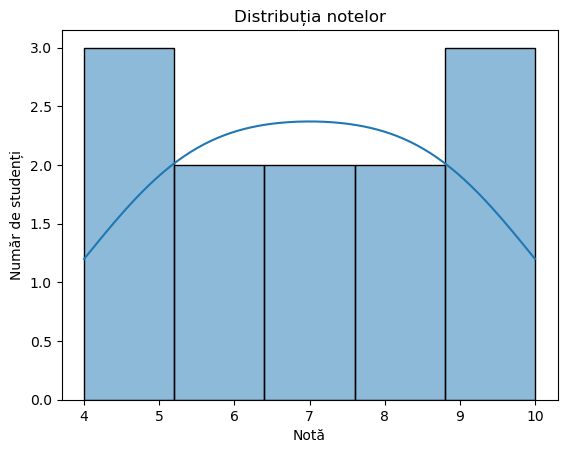

In [91]:
#Facem o histogramă pentru o variabilă numerică

sns.histplot(df['nota'], kde=True)
plt.title("Distribuția notelor")
plt.xlabel("Notă")
plt.ylabel("Număr de studenți")
plt.show()

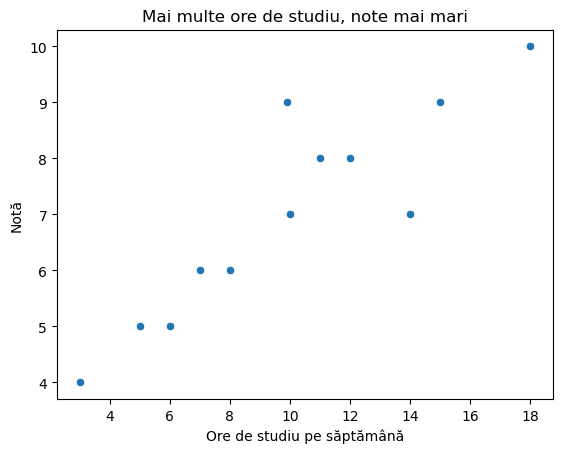

In [92]:
#Pentru a vizualiza relațile dintre variabile folosim un grafic de dispersie

sns.scatterplot(x='ore_studiu', y='nota', data=df)
plt.title("Mai multe ore de studiu, note mai mari")
plt.xlabel("Ore de studiu pe săptămână")
plt.ylabel("Notă")
plt.show()

**Greșeală frecventă:** `df.corr()` dă eroare dacă tabelul are coloane text, cum este și cazul nostru. Folosim aici `try`/`except` doar pentru a afișa eroarea fără a opri rularea notebook-ului:

In [93]:
try:
    df.corr()
except ValueError as e:
    print("Eroare:", e)

Eroare: could not convert string to float: 'Ana'


Soluția este `numeric_only=True`, care ia în calcul doar coloanele numerice:

,ore_studiu,puncte_activitate,nota
ore_studiu,1.000000,0.964438,0.898504
puncte_activitate,0.964438,1.000000,0.960028
nota,0.898504,0.960028,1.000000


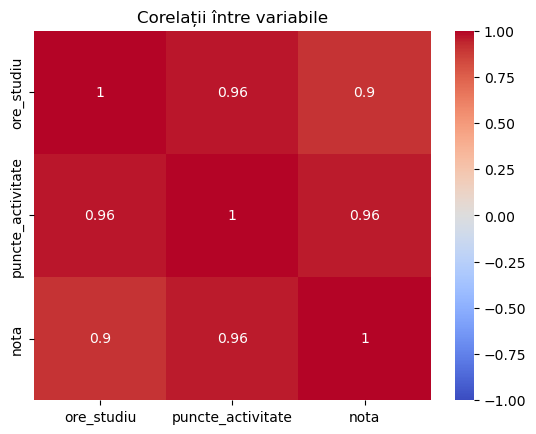

In [94]:
# Matricea de corelație
corelatii = df.corr(numeric_only=True)
display(corelatii)

# Heatmap cu corelațiile
sns.heatmap(corelatii, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Corelații între variabile")
plt.show()

<h2>Noțiuni de bază despre normalizare și standardizare</h2>

Normalizarea presupune scalarea datelor astfel încât valorile să fie cuprinse între 0 și 1.

In [95]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
date_normalizate = scaler.fit_transform(df[['ore_studiu', 'puncte_activitate']])

print(type(date_normalizate))

# Rezultatul este un array NumPy; îl punem într-un tabel ca să fie mai ușor de citit
normalizat = pd.DataFrame(date_normalizate, columns=['ore_studiu_norm', 'puncte_norm'])
display(pd.concat([df[['nume', 'ore_studiu', 'puncte_activitate']], normalizat], axis=1))
normalizat.agg(['min', 'max'])

<class 'numpy.ndarray'>


,nume,ore_studiu,puncte_activitate,ore_studiu_norm,puncte_norm
0,Ana,12.000000,640.0,0.600000,0.628205
1,Mihai,5.000000,210.0,0.133333,0.076923
2,Elena,9.909091,720.0,0.460606,0.730769
3,Radu,15.000000,810.0,0.800000,0.846154
4,Ioana,8.000000,390.0,0.333333,0.307692
5,Andrei,3.000000,150.0,0.000000,0.000000
6,Maria,18.000000,930.0,1.000000,1.000000
7,Vlad,10.000000,560.0,0.466667,0.525641
8,Sofia,7.000000,350.0,0.266667,0.256410
9,Dan,14.000000,700.0,0.733333,0.705128


,ore_studiu_norm,puncte_norm
min,0.0,0.0
max,1.0,1.0


Standardizarea presupune transformarea datelor astfel încât să aibă media 0 și deviația standard 1. Este utilă atunci când variabilele au distribuții normale.

In [96]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
date_standardizate = scaler.fit_transform(df[['ore_studiu', 'puncte_activitate']])

standardizat = pd.DataFrame(date_standardizate, columns=['ore_studiu_std', 'puncte_std'])
display(pd.concat([df[['nume', 'ore_studiu', 'puncte_activitate']], standardizat], axis=1))
standardizat.agg(['mean', 'std']).round(2) + 0  # + 0 afișează -0.00 ca 0.00

,nume,ore_studiu,puncte_activitate,ore_studiu_std,puncte_std
0,Ana,12.000000,640.0,0.496396,0.480041
1,Mihai,5.000000,210.0,-1.165453,-1.341292
2,Elena,9.909091,720.0,0.000000,0.818894
3,Radu,15.000000,810.0,1.208617,1.200103
4,Ioana,8.000000,390.0,-0.453232,-0.578873
5,Andrei,3.000000,150.0,-1.640267,-1.595431
6,Maria,18.000000,930.0,1.920838,1.708382
7,Vlad,10.000000,560.0,0.021582,0.141189
8,Sofia,7.000000,350.0,-0.690639,-0.748300
9,Dan,14.000000,700.0,0.971210,0.734181


,ore_studiu_std,puncte_std
mean,0.00,0.00
std,1.04,1.04


Deviația afișată este puțin peste 1 (1.04), dar nu este o greșeală: `StandardScaler` folosește deviația standard a populației, iar `.std()` din pandas pe cea a eșantionului. Diferența dintre ele se vede pe seturi mici de date și dispare pe măsură ce setul crește.

<h2>Rezumat</h2>

| Comandă | Ce face |
|---|---|
| `pd.read_csv(fisier)` | citește un CSV într-un DataFrame |
| `df.to_csv(fisier, mode="a", index=False, header=False)` | adaugă datele la finalul unui fișier |
| `display(df)` | afișează tabelul |
| `df.head()` | afișează primele 5 rânduri |
| `df.info()` | arată rândurile, tipurile și valorile existente |
| `df.describe()` | calculează statistici pentru coloanele numerice |
| `df.isnull().sum()` | numără valorile lipsă pe fiecare coloană |
| `df.dropna()` | șterge rândurile cu valori lipsă |
| `df.dropna(subset=[col])` | șterge rândurile la care lipsește valoarea din `col` |
| `df[col].fillna(df[col].mean())` | completează cu media |
| `df[col].fillna(df[col].median())` | completează cu mediana |
| `df[col].fillna(df[col].mode()[0])` | completează cu valoarea cea mai frecventă |
| `sns.histplot(...)` | arată distribuția unei coloane |
| `sns.scatterplot(...)` | arată relația dintre două coloane |
| `df.corr(numeric_only=True)` | calculează corelațiile |
| `sns.heatmap(...)` | desenează corelațiile colorat |
| `MinMaxScaler` | aduce valorile între 0 și 1 |
| `StandardScaler` | aduce valorile la media 0 și deviația standard 1 |

Datele sunt acum aproape gata pentru un model. Rămâne un singur aspect de care trebuie să ținem cont: `oras` este tot text, iar modelele din scikit-learn lucrează cu numere, așa că o astfel de coloană trebuie transformată în valori numerice sau lăsată deoparte. În Lecția 3 vom folosi date pregătite pentru a antrena primii algoritmi: regresia liniară și k-NN.

<h3>Mai multe link-uri folositoare:</h3>

https://numpy.org/doc/stable/ - Documentația Numpy

https://pandas.pydata.org/docs/ - Documentația Pandas

https://seaborn.pydata.org/tutorial/introduction - Documentația Seaborn

https://matplotlib.org/stable/index.html - Documentația Matplotlib

https://www.telework.ro/ro/preprocesarea-datelor-si-selectarea-caracteristicilor-in-nteligenta-artificiala/?srsltid=AfmBOoqPK9XR3yvMBDYkr_CG8_rd6YHO94mchiCWczXQVmxIXXw36_TV - Preprocesarea datelor și selectarea caracteristicilor în AI

https://www.tableau.com/learn/articles/what-is-data-cleaning - Tutorial pentru curățarea datelor

https://www.youtube.com/watch?v=6GUZXDef2U0 - Tutorial video Seaborn

https://www.youtube.com/watch?v=vmEHCJofslg - Tutorial video Pandas